### **1. Load Shapefile or GeoJSON**

In [ ]:
import geopandas as gpd
import matplotlib.pyplot as plt
from shapely.geometry import Point, LineString, Polygon

# Load sample geospatial vector data
url = "https://raw.githubusercontent.com/datasets/geo-countries/master/data/countries.geojson"
gdf = gpd.read_file(url)

### **2. Inspect CRS, Columns, and Geometry**

In [ ]:
print("CRS (Coordinate Reference System)")
print(gdf.crs)

CRS (Coordinate Reference System)
EPSG:4326


In [ ]:
print("Columns")
print(gdf.columns)

Columns
Index(['name', 'ISO3166-1-Alpha-3', 'ISO3166-1-Alpha-2', 'geometry'], dtype='object')


In [ ]:
print("First 5 Geometry Entries")
print(gdf.geometry.head())

First 5 Geometry Entries
0    MULTIPOLYGON (((117.70361 4.16342, 117.70361 4...
1    MULTIPOLYGON (((117.70361 4.16342, 117.69711 4...
2    MULTIPOLYGON (((-69.51009 -17.50659, -69.50611...
3    POLYGON ((-69.51009 -17.50659, -69.51009 -17.5...
4    MULTIPOLYGON (((-69.51009 -17.50659, -69.63832...
Name: geometry, dtype: geometry


### **3. Reproject Data to a Different CRS**

In [ ]:
# Reproject from WGS84 (EPSG:4326) to World Mercator (EPSG:3857) or UTM
gdf_projected = gdf.to_crs(epsg=3857)
print("Reprojected CRS")
print(gdf_projected.crs)

Reprojected CRS
EPSG:3857


### **4. Filter Features by Attribute**

In [ ]:
# Filtering features by attribute (e.g., selecting specific regions/countries)
filtered_gdf = gdf[gdf["name"] == "India"]
print("Filtered Feature")
print(filtered_gdf[["name", "geometry"]])

Filtered Feature
    name                                           geometry
8  India  MULTIPOLYGON (((77.80035 35.49541, 77.81533 35...


### **5. Create and Manipulate Geometric Objects (Shapely)**

In [ ]:
# Create Shapely geometries
point_a = Point(77.2090, 28.6139)  # New Delhi
point_b = Point(72.8777, 19.0760)  # Mumbai
line = LineString([point_a, point_b])

# Polygon around Delhi area
poly = Polygon([
    (77.0, 28.5),
    (77.4, 28.5),
    (77.4, 28.8),
    (77.0, 28.8)
])

# Spatial operations using Shapely & GeoPandas
buffer_zone = point_a.buffer(1.5)             # Buffering
intersection = poly.intersection(buffer_zone) # Intersection
union_geom = poly.union(buffer_zone)          # Union

### **6. Plot Vector Data using Matplotlib**

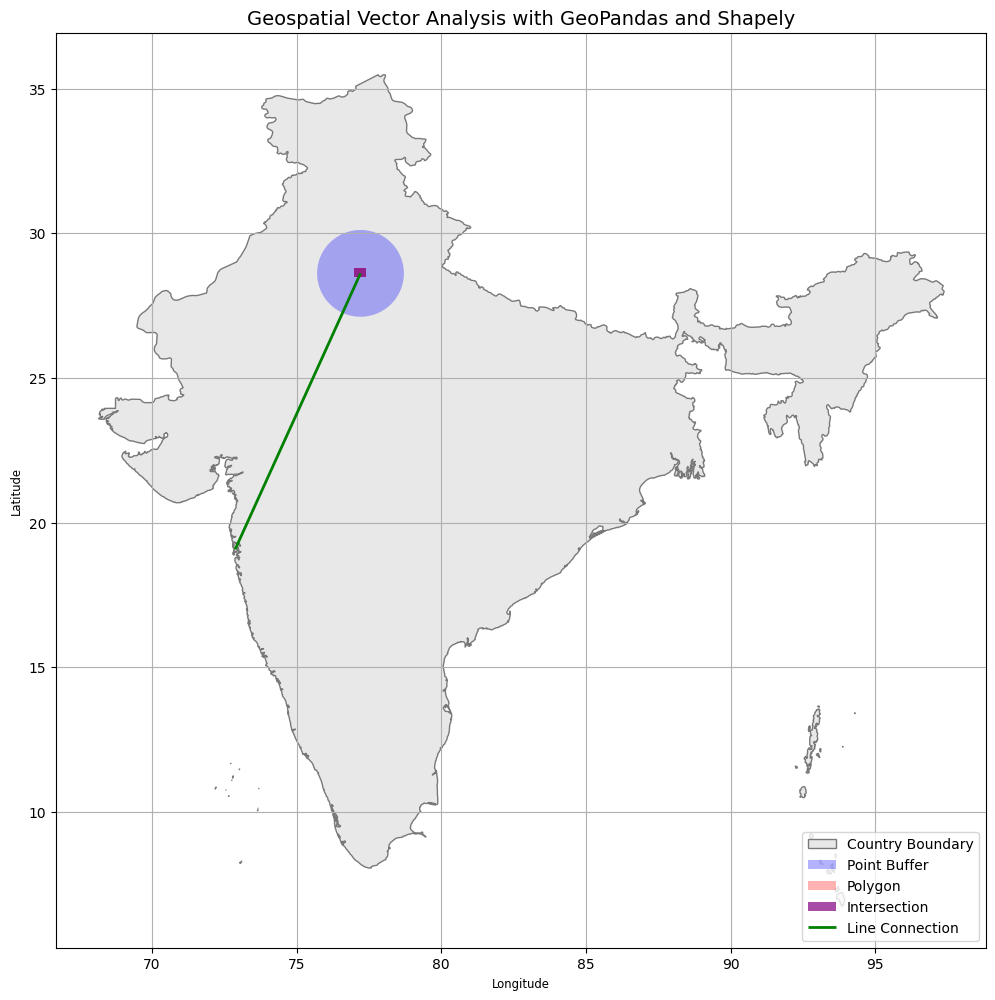

In [ ]:
fig, ax = plt.subplots(figsize=(12, 12))

# Plot base layer (Filtered country geometry)
filtered_gdf.plot(ax=ax, color="lightgrey", edgecolor="black", alpha=0.5, label="Country Boundary")

# Convert Shapely geometries to GeoDataFrame for plotting
spatial_ops_gdf = gpd.GeoDataFrame({"geometry": [poly, buffer_zone, intersection]}, crs="EPSG:4326")

# Plot Spatial Operations & Geometric Objects
gpd.GeoSeries([buffer_zone]).plot(ax=ax, color="blue", alpha=0.3, label="Point Buffer")
gpd.GeoSeries([poly]).plot(ax=ax, color="red", alpha=0.3, label="Polygon")
gpd.GeoSeries([intersection]).plot(ax=ax, color="purple", alpha=0.7, label="Intersection")
gpd.GeoSeries([line]).plot(ax=ax, color="green", linewidth=2, label="Line Connection")

# Customize plot
plt.title("Geospatial Vector Analysis with GeoPandas and Shapely", fontsize=14)
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.legend(loc="lower right")
plt.grid(True)

plt.show()

### **Interpretation**

Based on the analysis and visualization performed in this lab, we can draw the following interpretations:

* **Coordinate Reference System (CRS) Verification:** The original dataset was successfully loaded in the **EPSG:4326 (WGS84)** geographic coordinate system, which uses latitude and longitude coordinates. We verified that we could reproject this dataset into a projected coordinate system (**EPSG:3857 - Web Mercator**) suitable for distance calculations and planar mapping.

* **Geospatial Filtering:** We successfully query-filtered the global countries dataset using attribute criteria (`name == 'India'`) to extract a clean base-map boundary layer.

* **Geometric Operations (Shapely):**

    * **Point Buffer:** A 1.5-degree buffer was calculated around the coordinate point representing **New Delhi** (Point A). This created a spatial circular zone of influence representing proximity.

    * **Polygon Intersection:** We defined a rectangular bounding area (Polygon) over the Delhi region. By intersecting the circular buffer zone with this rectangular polygon, we successfully isolated the spatial region common to both features (rendered as the purple intersection on the map).
    
    * **Line Connection:** A direct spatial vector line connection was established between the coordinates of **New Delhi** and **Mumbai**, highlighting the spatial relationship between two major urban centers.

### **Conclusion**

In this laboratory experiment, we successfully demonstrated the fundamentals of handling vector GIS data using Python's scientific ecosystem, specifically **GeoPandas**, **Shapely**, and **Matplotlib**.

By completing this lab, we achieved the following core objectives:
1. **Data Ingestion & Inspection:** Learned how to import GeoJSON data directly from a remote URL, inspect the schema, attribute columns, and evaluate the internal coordinate reference system (CRS).

2. **Projections & Transformation:** Gained hands-on experience in reprojecting spatial datasets between geographic (EPSG:4326) and projected (EPSG:3857) systems.

3. **Spatial Queries & Geoprocessing:** Mastered attribute-based filtering to slice vector layers and used Shapely to execute topological spatial relations (buffers, unions, and intersections).

4. **Geovisualization:** Layered multiple independent spatial data sources (a base-map country boundary, point buffers, user-defined polygons, and line strings) onto a single coordinate space to create a publication-ready geospatial visualization.

Ultimately, this lab highlights Python's efficiency as a complete programmatic alternative to desktop GIS applications (like QGIS or ArcGIS) for reproducible spatial data science workflows.

### **Colab File:** https://colab.research.google.com/drive/1OOdwmtb-62ZlYys0eAkopOR2a7ybZvj1?usp=sharing
